In [378]:
import sys
import os
import json
import math

from matplotlib import pyplot as plt
from wordfreq import top_n_list, zipf_frequency

from src.tasks import scraper as s
from src.tasks import count_words as c

# Dodajemy katalog tasks do ścieżki, żeby można było importować z tego katalogu
BASE_DIR = os.getcwd()
TASK_DIR = os.path.join(BASE_DIR, "tasks")
sys.path.insert(0, TASK_DIR)

url_to_scrape = "https://bulbapedia.bulbagarden.net/wiki/"

In [379]:
# 1
# lista 1500 najczęściej używanych słów w 3 językach (polski, angielski i niemiecki)
top_pl = top_n_list("pl", 1500)
top_en = top_n_list("en", 1500)
top_de = top_n_list("de", 1500)

In [380]:
# 2
# Tworzymy słownik dla artykułu zawierającego >= 5000 słów z wiki o "Team Rocket"
scraper = s.Scraper(url_to_scrape, "Team Rocket")
scraped_data_t = scraper.scrape()
c.count(scraped_data_t, "wiki_article.json")

In [381]:
# Zwraca liczbę oznaczającą jak bardzo tekst pasuje do danego języka
def lang_confidence_score(word_counts, language_words_with_frequency):
    score = 0.0
    total = 0

    for word, count in word_counts.items():
        total += count
        if word in language_words_with_frequency:
            freq = language_words_with_frequency[word]
            score += math.log(freq) * count
        else:  # Kara za to, że słowo spoza języka
            score -= 0.3 * count
    # Normalizujemy, żeby długość tekstu nie dominowała
    return score / max(total, 1)

In [382]:
# 3
# Tworzymy słownik dla artykułu z wiki o "U-turn", który ma możliwie niski wynik funkcji względem innych języków
scraper_l = s.Scraper(url_to_scrape, "U-turn")
scraped_data_l = scraper_l.scrape()
c.count(scraped_data_l, "wiki_article_worst_case.json")

In [383]:
# Artykuł pl: https://grajmerki.pl/historia-pokemon/
with open("text_pl.txt", "r") as f:
    text = f.read()
c.count(text, "text_in_pl.json")

# Artykuł en: https://www.tcgplayer.com/content/article/The-Biggest-Price-Spikes-in-Pokémon-this-Week-01-27-2026/a03c96bd-192b-4a12-8029-61bc7e2664d3/
with open("text_en.txt", "r") as f:
    text = f.read()
c.count(text, "text_in_en.json")

# Artykuł de: https://www.pokemon.com/de/pokemon-news/europaeische-internationalmeisterschaften-2026-vorschau-nebenveranstaltungen-und-mehr
with open("text_de.txt", "r") as f:
    text = f.read()
c.count(text, "text_in_de.json")


In [384]:
languages = ["pl", "en", "de"]
all_ks = [3, 10, 100, 1000]

files = {
    "wiki (en) ": "wiki_article.json",
    "wiki_worst_case (en) ": "wiki_article_worst_case.json",
    "text_pl": "text_in_pl.json",
    "text_en": "text_in_en.json",
    "text_in_de": "text_in_de.json",
}


In [385]:
def build_frequency(lang, k):
    words = top_n_list(lang, k)
    return {
        word: zipf_frequency(word, lang) for word in words
    }

In [386]:
def load_words_count(path):
    with open(path, "r") as file:
        return json.loads(file.read())

In [387]:
words_counts = {
    name: load_words_count(path) for name, path in files.items()
}

In [388]:
def generate_all_frequencies(lang, ks):
    freqs = {}
    for l in lang:
        freqs[l] = {}
        for k in ks:
            freqs[l][k] = build_frequency(l, k)
    return freqs

In [389]:
frequencies = generate_all_frequencies(languages, all_ks)

In [390]:
def generate_all_answers(word_counts, freqs, langs, ks):
    answers = {}
    for text_name, wc in word_counts.items():
        answers[text_name] = {}
        for k in ks:
            answers[text_name][k] = {}
            for lang in langs:
                score = lang_confidence_score(wc, freqs[lang][k])
                answers[text_name][k][lang] = score
    return answers

In [400]:
def generate_plot(results, name, languages, ks):
    plt.figure(figsize=(8, 5))

    for lang in languages:
        scores = [results[name][k][lang] for k in ks]
        plt.plot(ks, scores, marker="o", linewidth=2, label=lang)
        plt.ylim(-0.4, 1.25)

    plt.xscale("log")
    plt.axhline(0, color="white", linestyle="--", linewidth=1)
    plt.xticks(ks, ks)

    plt.xlabel("k")
    plt.ylabel("confidence score")
    plt.title(f"Chart for {name}")

    plt.grid(alpha=0.3)
    plt.legend(title="Language")
    plt.tight_layout()
    plt.show()

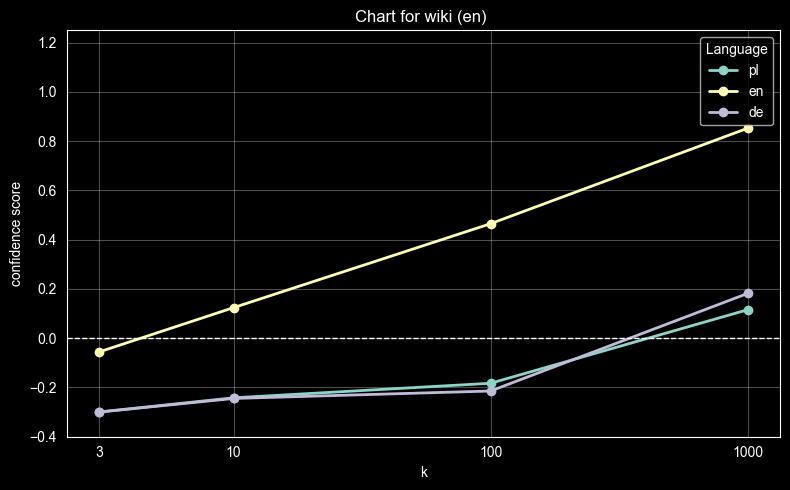

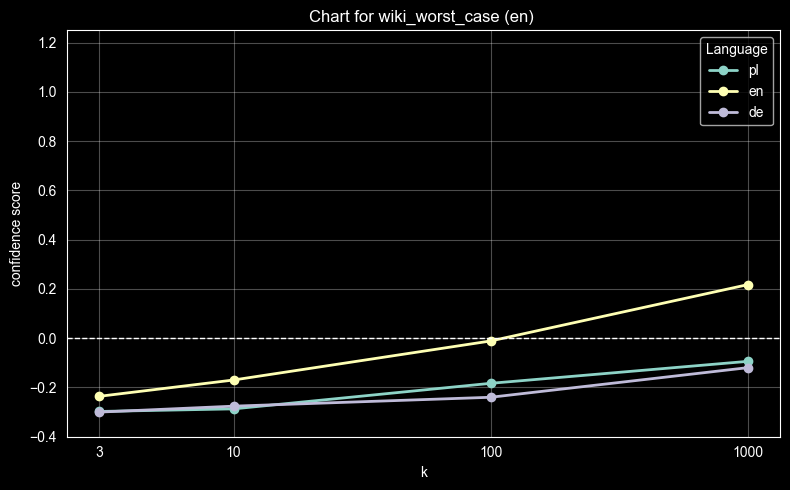

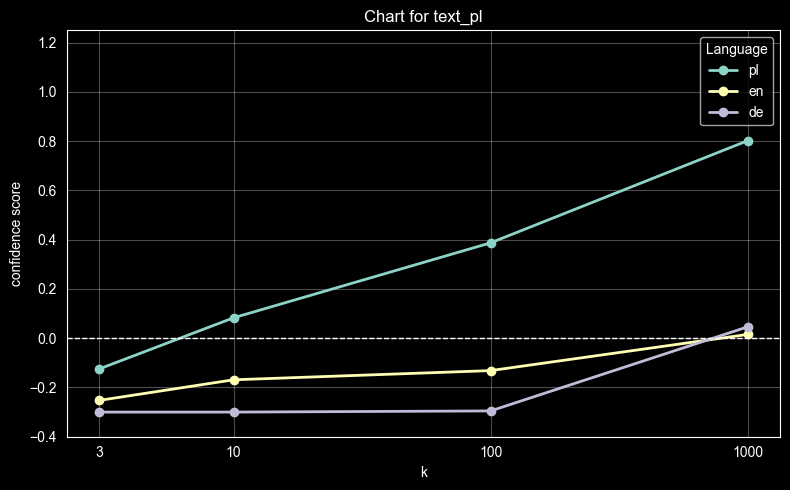

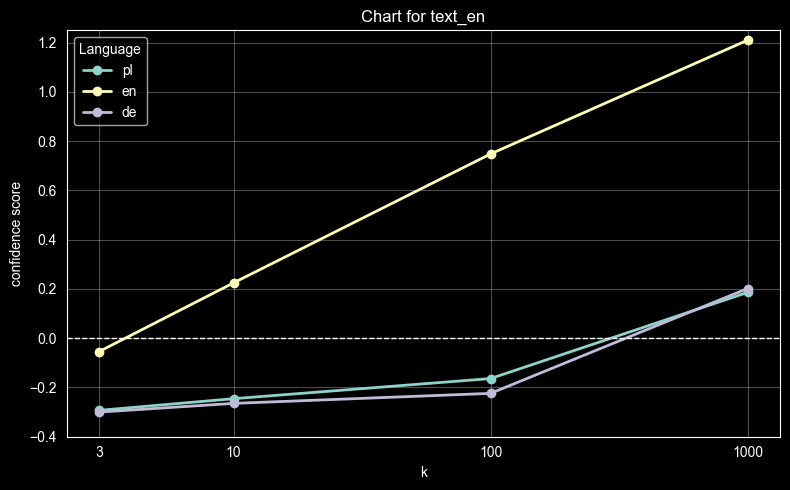

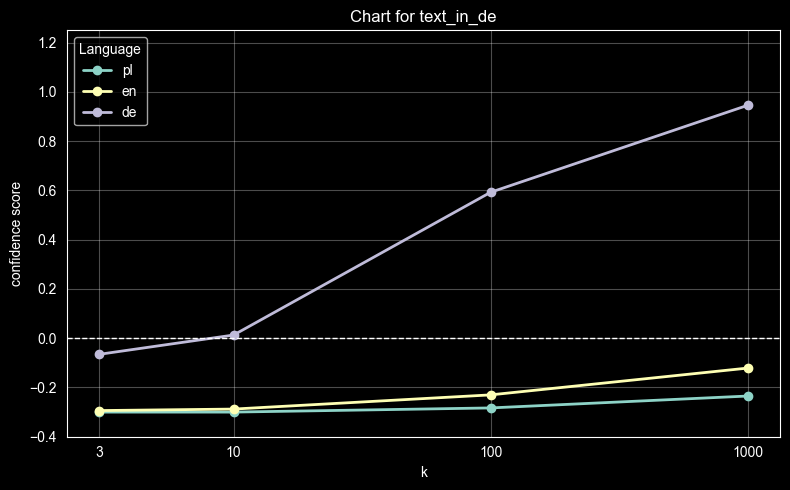

In [401]:
res = generate_all_answers(words_counts, frequencies, languages, all_ks)

for text_name, k_results in res.items():
    generate_plot(res, text_name, languages, all_ks)


###### WYNIK EMPIRYCZNY SKUTECZNOŚCI MOJEJ METODY WYKRYWANIA DOPASOWANIA SŁÓW Z DANYCH DO NAJCZĘSTSZYCH "k" SŁÓW W DANYM JĘZYKU


Na wykresach można zaobserwować, że największą skuteczność zaprojektowana przeze mnie metoda wykrywania dopasowania słów osiąga w przypadku anglojęzycznych artykułów (zarówno artykuł wiki, jak i również artykuł spoza wiki) oraz dla największego *k*. Zobrazowane jest to najwyższą wartością skuteczności (\~1.2) dla największej liczby k (=1000). Jednocześnie warto zwrócić uwagę na stały, proporcjonalny wzrost dopasowania wraz z rosnącym k. W przypadku artykułów w języku niemieckim i polskim można dostrzec niższą wartość maksymalnego dopasowania (odpowiednio \~1 i \~0.8) przy mniej proporcjonalnym wzroście. Może to wskazywać na występowanie w tych językach większej różnorodności tego samego słowa (przez to dla mniejszej bazy popularnych słów tracimy wtedy na dokładności).



* Czy dobór języków miał duże znaczenie?
    * Dobór języków miał znaczenie, róźnicę w skuteczności dla największego *k* można oszacować od 20% (pomiędzy text_de a text_en) do 40% (pomiędzy text_pl a text_en) - zgodnie ze wskazanymi wartościami maksymalnymi na wykresie.

* Czy po wartościach language_words_with_frequency dla danych i najczęstszych
słowach z języka danych widać, że w wybranym języku słowa często są odmieniane?
    * Analizując poszczególne wykresy (text_pl, text_en, text_de, wiki) można zauważyć, że artykuły oraz wiki anglojęzyczne dają większe dopasowania niż np. polskie, w których częściej odmienia się słowa.

* Czy trudne było znalezienie takiego artykułu, dla którego wynik
language_words_with_frequency jest jak najmniejszy w języku wiki? Czy to
specyfika tego wiki?
    * W przypadku _BULBAPEDII_ wiele artykułów zawiera dużo nazw własnych, przez co było to prostsze zadanie, jednak zajęło ono mimo wszystko co najmniej kilkanaście prób.